#### Imports

In [2]:
import matplotlib.pyplot as plt
import seaborn as sn
import numpy as np
import pandas as pd

## Get the Data

In [8]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print(train_df.info())
print(train_df.head(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   season     900 non-null    object 
 1   price_AUS  638 non-null    float64
 2   price_CHF  631 non-null    float64
 3   price_CZE  632 non-null    float64
 4   price_GER  631 non-null    float64
 5   price_ESP  631 non-null    float64
 6   price_FRA  636 non-null    float64
 7   price_UK   613 non-null    float64
 8   price_ITA  634 non-null    float64
 9   price_POL  635 non-null    float64
 10  price_SVK  619 non-null    float64
dtypes: float64(10), object(1)
memory usage: 77.5+ KB
None
   season  price_AUS  price_CHF  price_CZE  price_GER  price_ESP  price_FRA  \
0  spring        NaN   9.644028  -1.686248  -1.748076  -3.666005        NaN   
1  summer        NaN   7.246061  -2.132377  -2.054363  -3.295697  -4.104759   
2  autumn  -2.101937   7.620085  -1.910282        NaN  -3.388777        NaN   


Note: All attributes except season have NULL values and "season" is a categorical attribute

season
spring    225
summer    225
autumn    225
winter    225
Name: count, dtype: int64

        price_AUS   price_CHF   price_CZE   price_GER   price_ESP   price_FRA  \
count  638.000000  631.000000  632.000000  631.000000  631.000000  636.000000   
mean    -0.665411    4.538611   -0.221514   -0.421923   -4.737647   -2.914028   
std      1.016447    3.328953    1.192286    1.155131    1.186441    1.102510   
min     -2.362783   -3.736940   -2.147384   -2.238546   -6.891480   -4.428215   
25%     -1.613550    2.640888   -1.522282   -1.633691   -5.688912   -3.884357   
50%     -0.577244    3.872916    0.198743   -0.251429   -4.514822   -3.291359   
75%      0.005234    7.736682    0.784038    0.646908   -3.603188   -2.025672   
max      1.316798    9.933313    1.710173    1.659539   -2.858268    0.000619   

         price_UK   price_ITA   price_POL   price_SVK  
count  613.000000  634.000000  635.000000  619.000000  
mean    -1.518137   -2.686282   -0.296811   -0.643735  
std      1.6

array([[<Axes: title={'center': 'price_AUS'}>,
        <Axes: title={'center': 'price_CHF'}>,
        <Axes: title={'center': 'price_CZE'}>],
       [<Axes: title={'center': 'price_GER'}>,
        <Axes: title={'center': 'price_ESP'}>,
        <Axes: title={'center': 'price_FRA'}>],
       [<Axes: title={'center': 'price_UK'}>,
        <Axes: title={'center': 'price_ITA'}>,
        <Axes: title={'center': 'price_POL'}>],
       [<Axes: title={'center': 'price_SVK'}>, <Axes: >, <Axes: >]],
      dtype=object)

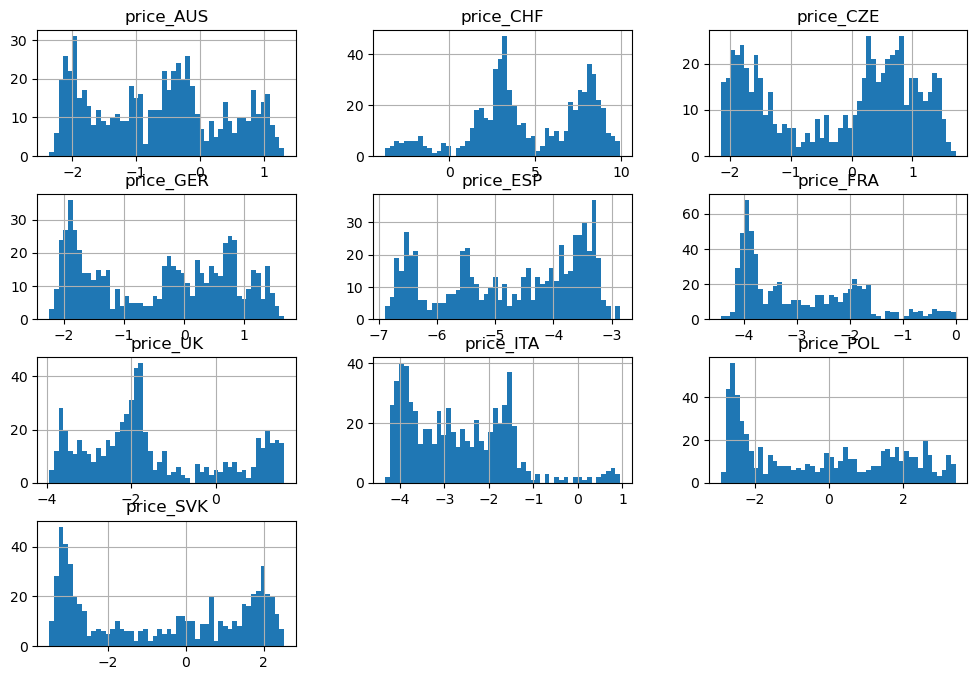

In [32]:
#What are possible categorical attributes for "season"
print(train_df["season"].value_counts())

print()
#Summary of numerical attributes - null values are ignored
print(train_df.describe())

#histograms
train_df.hist(bins=50,figsize=(12,8))

## Visualization


           price_AUS  price_CHF  price_CZE  price_GER  price_ESP  price_FRA  \
price_AUS   1.000000  -0.729917   0.921013   0.820890  -0.614548   0.718825   
price_CHF  -0.729917   1.000000  -0.861839  -0.906182   0.524959  -0.889028   
price_CZE   0.921013  -0.861839   1.000000   0.943531  -0.617783   0.818431   
price_GER   0.820890  -0.906182   0.943531   1.000000  -0.615882   0.895700   
price_ESP  -0.614548   0.524959  -0.617783  -0.615882   1.000000  -0.300146   
price_FRA   0.718825  -0.889028   0.818431   0.895700  -0.300146   1.000000   
price_UK   -0.051041  -0.380633   0.217981   0.320854  -0.543645   0.181871   
price_ITA   0.801979  -0.912357   0.879080   0.906797  -0.425671   0.953741   
price_POL   0.643474  -0.923023   0.838389   0.886958  -0.357590   0.879563   
price_SVK   0.759934  -0.908748   0.906237   0.895127  -0.435271   0.867818   

           price_UK  price_ITA  price_POL  price_SVK  
price_AUS -0.051041   0.801979   0.643474   0.759934  
price_CHF -0.380633 

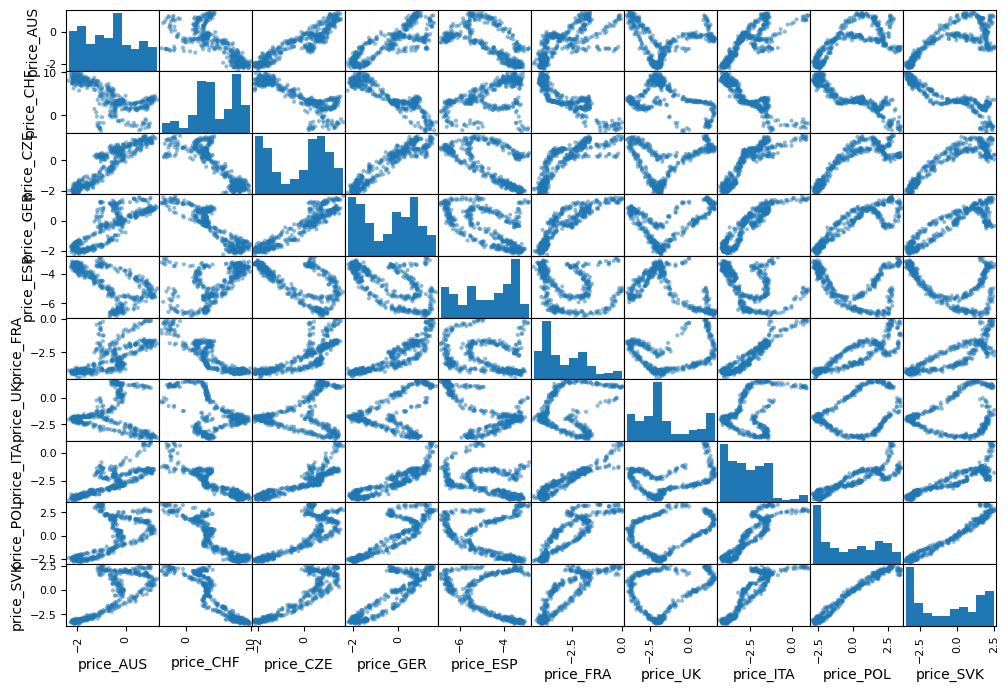

In [36]:
train_noSeason = train_df.drop(['season'],axis=1) #drop nonnumerical attribute
corr_matrix = train_noSeason.corr()
#close to 1: strong positive correlation; close to -1: strong negative correlation
print(corr_matrix)
print()
print(corr_matrix["price_CHF"].sort_values(ascending=False))
scatter_matrix = pd.plotting.scatter_matrix(train_noSeason,figsize=(12,8))

Note: How does negative correlation even make sense in this context? If the prices go down in one country, why do the prices in another go up?

## Preprocessing

In [1]:
print(X_train.info())
print(X_train.head(3))
print(X_test.info())
print(X_test.head(3))
X_train = train_df.drop(columns=['price_CHF'])
y_train = train_df['price_CHF']
X_test = test_df

pipe = Pipeline(['imputer',IterativeImputer(initial_strategy="mean"), ('encoder',OneHotEncoder())])
pipe.fit(X_train,y_train)
X_train = pipe.transform(X_train)
X_test = pipe.transform(X_test)

print("Transformed Data: ")
print(X_train.info())
print(X_train.head(3))
print(X_test.info())
print(X_test.head(3))

NameError: name 'X_train' is not defined